# 03 · Reducción de dimensionalidad (PCA)
**Responsable:** Santiago · **Módulo 3**

**Objetivo.** Reducir las 10 variables acústicas a pocas componentes, entender qué representa cada una y dejar lista
la matriz `X_pca.csv` para el clustering de Juan.

Se parte de la matriz estandarizada del notebook 02 (ejecutarlo antes).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config as cfg
from src import preprocessing as pp
from src import viz

viz.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Carga de la matriz preprocesada

In [2]:
songs, Xs_ids = pp.load_preprocessed()
Xs = Xs_ids.drop(columns=[cfg.ID_COL])
print(Xs.shape)

(81198, 10)


## 2. Ajuste de PCA y varianza explicada
Se elige el menor número de componentes `k` cuya varianza acumulada alcanza el objetivo definido en
`cfg.PCA_VARIANCE_TARGET`. Como apoyo se reporta el criterio de Kaiser (autovalor > 1, válido porque los datos están estandarizados) y se busca el "codo" en el gráfico.

In [3]:
pca, k, var_table, scores, loadings = pp.fit_pca(Xs)
print(f"{k} componentes explican {var_table.varianza_acumulada.iloc[k-1]:.1%} de la varianza (objetivo {cfg.PCA_VARIANCE_TARGET:.0%})")
print(f"Criterio de Kaiser (autovalor > 1): {int((var_table.autovalor > 1).sum())} componentes")
var_table

7 componentes explican 90.9% de la varianza (objetivo 90%)
Criterio de Kaiser (autovalor > 1): 3 componentes


,componente,autovalor,varianza_explicada,varianza_acumulada
0,PC1,2.878,0.288,0.288
1,PC2,1.548,0.155,0.443
2,PC3,1.270,0.127,0.570
3,PC4,0.949,0.095,0.665
4,PC5,0.905,0.090,0.755
5,PC6,0.805,0.080,0.836
6,PC7,0.734,0.073,0.909
7,PC8,0.447,0.045,0.954
8,PC9,0.325,0.032,0.986
9,PC10,0.138,0.014,1.000


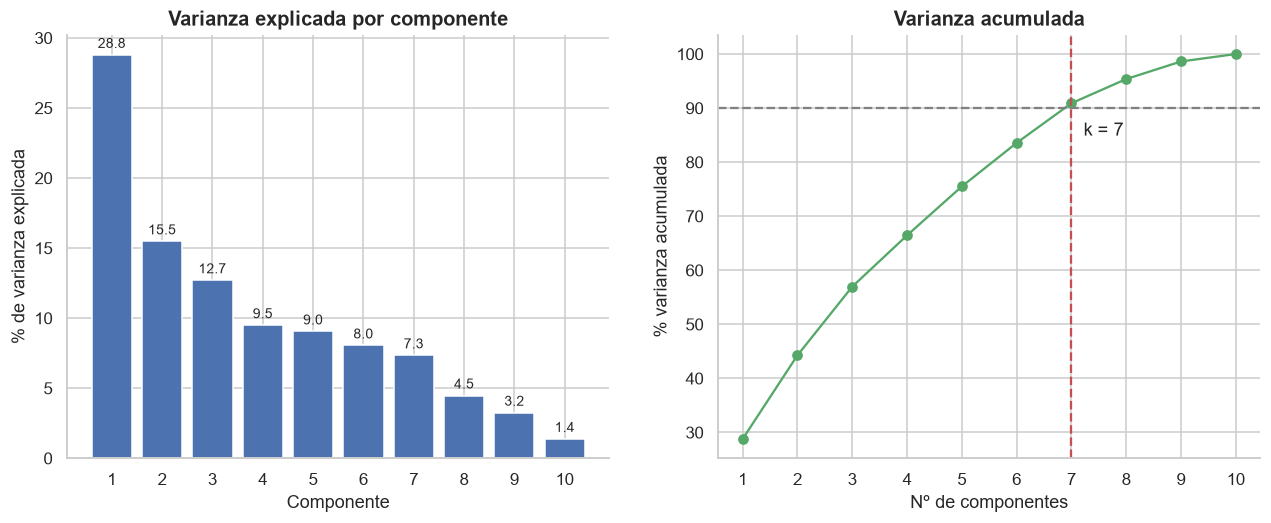

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(1, len(var_table) + 1)
bars = axes[0].bar(x, var_table.varianza_explicada * 100, color=viz.PALETTE[0])
for b, v in zip(bars, var_table.varianza_explicada * 100):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}", ha="center", fontsize=9)
axes[0].set_xlabel("Componente"); axes[0].set_ylabel("% de varianza explicada")
axes[0].set_title("Varianza explicada por componente"); axes[0].set_xticks(x)

axes[1].plot(x, var_table.varianza_acumulada * 100, "o-", color=viz.PALETTE[2])
axes[1].axhline(cfg.PCA_VARIANCE_TARGET * 100, ls="--", color="gray")
axes[1].axvline(k, ls="--", color=viz.PALETTE[3])
axes[1].annotate(f"k = {k}", (k, cfg.PCA_VARIANCE_TARGET * 100), textcoords="offset points", xytext=(8, -18))
axes[1].set_xlabel("Nº de componentes"); axes[1].set_ylabel("% varianza acumulada")
axes[1].set_title("Varianza acumulada"); axes[1].set_xticks(x)
viz.save_fig(fig, "pca_01_varianza")
plt.show()

## 3. ¿Qué significa cada componente? (loadings)
Los *loadings* son la correlación entre cada variable original y cada componente. Valores altos en valor absoluto
indican qué variables "construyen" esa componente. **Aquí se ponen nombre a PC1, PC2, …** para el informe.

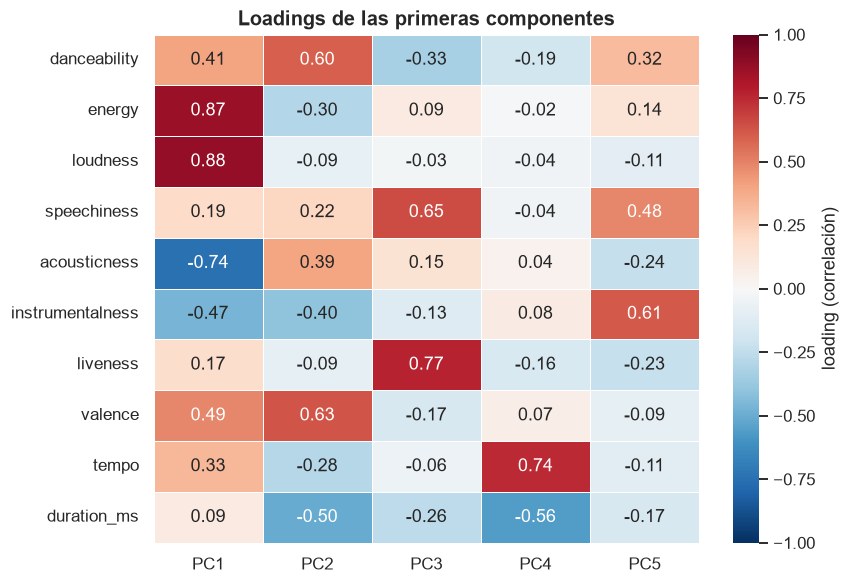

PC1: loudness (+0.88), energy (+0.87), acousticness (-0.74)
PC2: valence (+0.63), danceability (+0.60), duration_ms (-0.50)
PC3: liveness (+0.77), speechiness (+0.65), danceability (-0.33)


In [5]:
mostrar = loadings.iloc[:, :min(k, 5)]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(mostrar, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.5, ax=ax, cbar_kws={"label": "loading (correlación)"})
ax.grid(False)
ax.set_title("Loadings de las primeras componentes")
viz.save_fig(fig, "pca_02_loadings")
plt.show()

for pc in mostrar.columns[:3]:
    top = mostrar[pc].abs().sort_values(ascending=False).head(3).index
    print(f"{pc}: " + ", ".join(f"{v} ({mostrar.loc[v, pc]:+.2f})" for v in top))

## 4. Espacio reducido: PC1 vs PC2

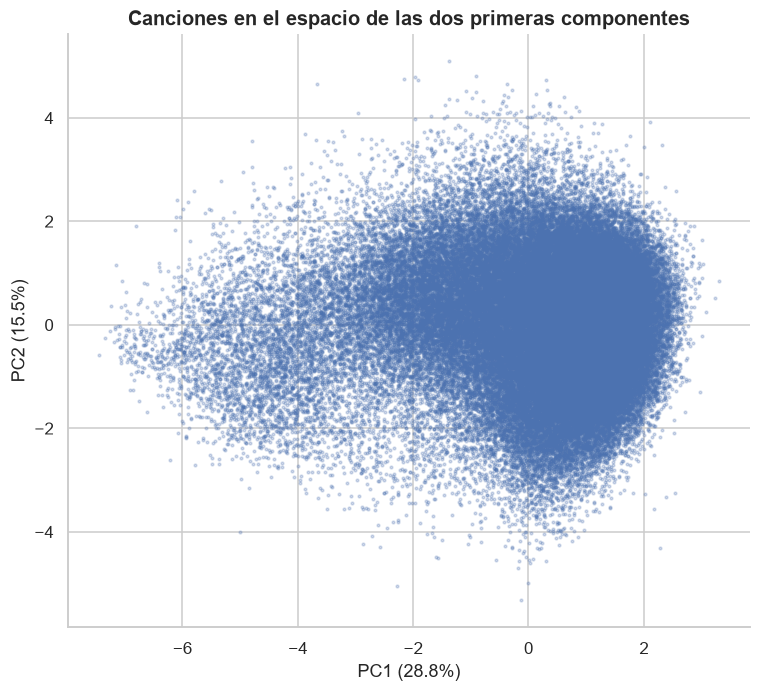

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(scores["PC1"], scores["PC2"], s=3, alpha=.25, color=viz.PALETTE[0], rasterized=True)
ax.set_xlabel(f"PC1 ({var_table.varianza_explicada.iloc[0]:.1%})")
ax.set_ylabel(f"PC2 ({var_table.varianza_explicada.iloc[1]:.1%})")
ax.set_title("Canciones en el espacio de las dos primeras componentes")
viz.save_fig(fig, "pca_03_scatter")
plt.show()

### 4.1 Mismo espacio, coloreado por género (solo para visualizar)
> **Atención metodológica:** el género **no** se usó para ajustar PCA. Se pinta *después*, solo para ver si el espacio
> reducido tiene algún orden relacionado con el género. Se muestran los 8 géneros más frecuentes.

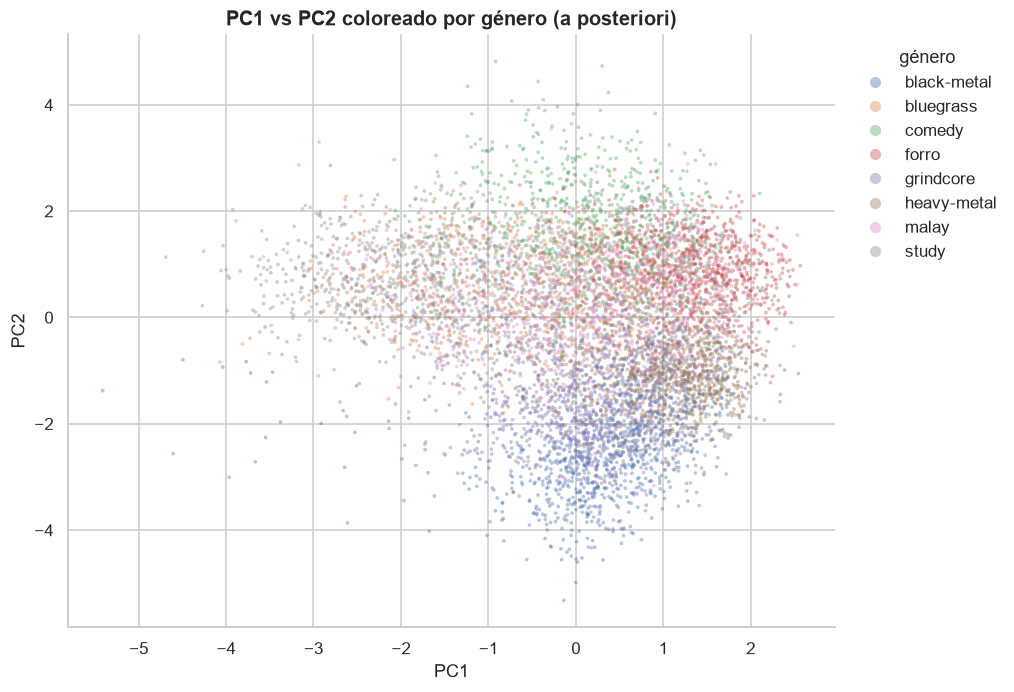

In [7]:
top_gen = songs["primary_genre"].value_counts().head(8).index
mask = songs["primary_genre"].isin(top_gen).values
fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(x=scores.loc[mask, "PC1"], y=scores.loc[mask, "PC2"],
                hue=songs.loc[mask, "primary_genre"], s=6, alpha=.4, ax=ax,
                palette=viz.PALETTE[:8], rasterized=True, linewidth=0)
ax.legend(markerscale=3, title="género", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("PC1 vs PC2 coloreado por género (a posteriori)")
viz.save_fig(fig, "pca_04_scatter_genero")
plt.show()

## 5. Biplot: variables y canciones juntas
Las flechas muestran hacia dónde "empuja" cada variable original en el plano PC1–PC2.

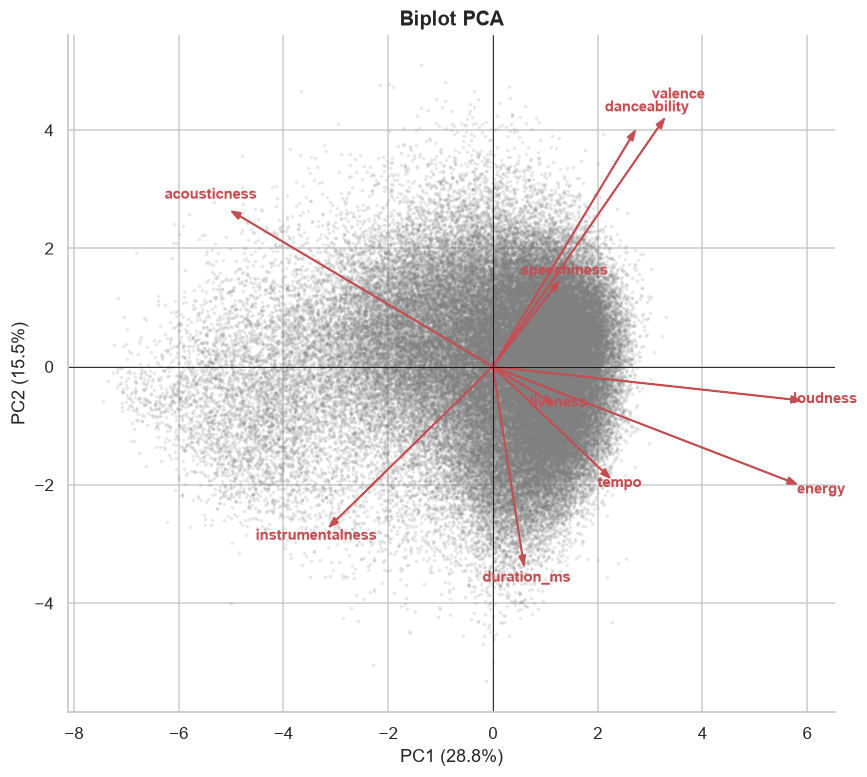

In [8]:
fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(scores["PC1"], scores["PC2"], s=2, alpha=.12, color="gray", rasterized=True)
escala = 0.9 * max(scores["PC1"].abs().max(), scores["PC2"].abs().max())
for var in loadings.index:
    ax.arrow(0, 0, loadings.loc[var, "PC1"] * escala, loadings.loc[var, "PC2"] * escala,
             color=viz.PALETTE[3], width=0.01, head_width=0.12, length_includes_head=True)
    ax.text(loadings.loc[var, "PC1"] * escala * 1.08, loadings.loc[var, "PC2"] * escala * 1.08,
            var, color=viz.PALETTE[3], fontsize=10, fontweight="bold", ha="center")
ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
ax.set_xlabel(f"PC1 ({var_table.varianza_explicada.iloc[0]:.1%})")
ax.set_ylabel(f"PC2 ({var_table.varianza_explicada.iloc[1]:.1%})")
ax.set_title("Biplot PCA")
viz.save_fig(fig, "pca_05_biplot")
plt.show()

## 6. Guardado para Juan

In [9]:
pp.save_pca(songs[[cfg.ID_COL]], pca, k, scores, var_table, loadings)
chk = pd.read_csv(cfg.DATA_PROCESSED / "X_pca.csv")
assert len(chk) == len(songs) and (chk[cfg.ID_COL].values == songs[cfg.ID_COL].values).all()
print(f"X_pca.csv listo: {chk.shape[0]:,} filas x {chk.shape[1] - 1} componentes")

X_pca.csv listo: 81,198 filas x 7 componentes


## 7. Interpretación para el informe
> **Completar en equipo tras ejecutar:**
> - Nombre e interpretación de PC1 y PC2 según sus loadings (ej.: "eje de intensidad: energy, loudness frente a acousticness").
> - Cuántas componentes se retienen y qué % de varianza representan; si el codo del scree plot coincide con ese `k`.
> - Qué muestra el scatter coloreado por género: ¿hay zonas dominadas por un género o todo se superpone?
> - Limitación: PCA es lineal; estructuras no lineales no se capturan (se podría mencionar t-SNE/UMAP como trabajo futuro).